# v5_simplify — v3c 단순화(parsimony) 검증

**질문.** 주모델 v3c(14개 변수)에서 잉여 변수를 떨궈 **더 간결한 모델**을 만들 수 있나?
손실 없이?

**방법.** v3c에서 ① **Leave-One-Out**(변수 1개씩 제거 효과) → ② **BIC 후방제거**
(BIC를 가장 낮추는 변수를 반복 제거, 더 못 낮추면 종료) → ③ **v3c vs v5 head-to-head**.
선택 구동 = **학습내 BIC**(벌점 ln n≈8.61/변수 > AIC의 2). 2025 홀드아웃은 확인용(봉인).

**결과 미리.** greedy(`v5_greedy`)가 어느 window에서도 안 고른 4개
(`ws_avg`·`pop_total`·`heat/cold_th_2day_any`)가 BIC로도 떨어져 **14→10**. AIC −5.5·
BIC −32로 오히려 개선, rolling MAE도 −2.8. → 이 4개는 **확실한 잉여**.
상세: `docs/research_log/2026-05-30_1730_v5_단순화_검증.md` · 계보: `src/MODELS.md`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager
import seaborn as sns

warnings.filterwarnings("ignore")
# 한글 폰트 (eda/modeling.ipynb와 동일)
NOTO_PATH = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if NOTO_PATH.exists():
    font_manager.fontManager.addfont(str(NOTO_PATH))
KOR_FONT = "Noto Sans CJK JP"
mpl.rcParams["font.family"] = KOR_FONT
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", rc={"font.family": KOR_FONT})

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
ARI = ROOT / "data" / "processed" / "arimax"
print("ARI:", ARI)

res = pd.read_csv(ARI / "v5_results.csv", encoding="utf-8-sig")
abl = pd.read_csv(ARI / "v5_ablation.csv", encoding="utf-8-sig")
fc  = pd.read_csv(ARI / "v5c_forecast.csv", encoding="utf-8-sig", parse_dates=["tm"]).set_index("tm")
res[["model", "n_exog", "AIC", "BIC", "MAE_2025", "MAE_2025_rolling", "Winkler", "PI95_cov_%"]].round(2)

ARI: /home/jmlee/research/timeseries-final/data/processed/arimax


,model,n_exog,AIC,BIC,MAE_2025,MAE_2025_rolling,Winkler,PI95_cov_%
0,v3c,14,-23830.96,-23698.85,2667.51,1357.31,18304.86,95.34
1,v5_bic_backward,10,-23836.49,-23730.80,2670.44,1354.47,18416.26,95.34
2,v5_drop4,10,-23836.49,-23730.80,2670.44,NaN,18416.26,95.34


## 1. Leave-One-Out 진단 — 잉여 4개 vs 필수 10개

v3c에서 변수를 1개씩 빼본 효과. **ΔBIC<0 = 제거가 이득(잉여)**, 빨강 = 계수 p>0.05.
두 무리로 **깨끗이 분리**(중간 지대 없음).

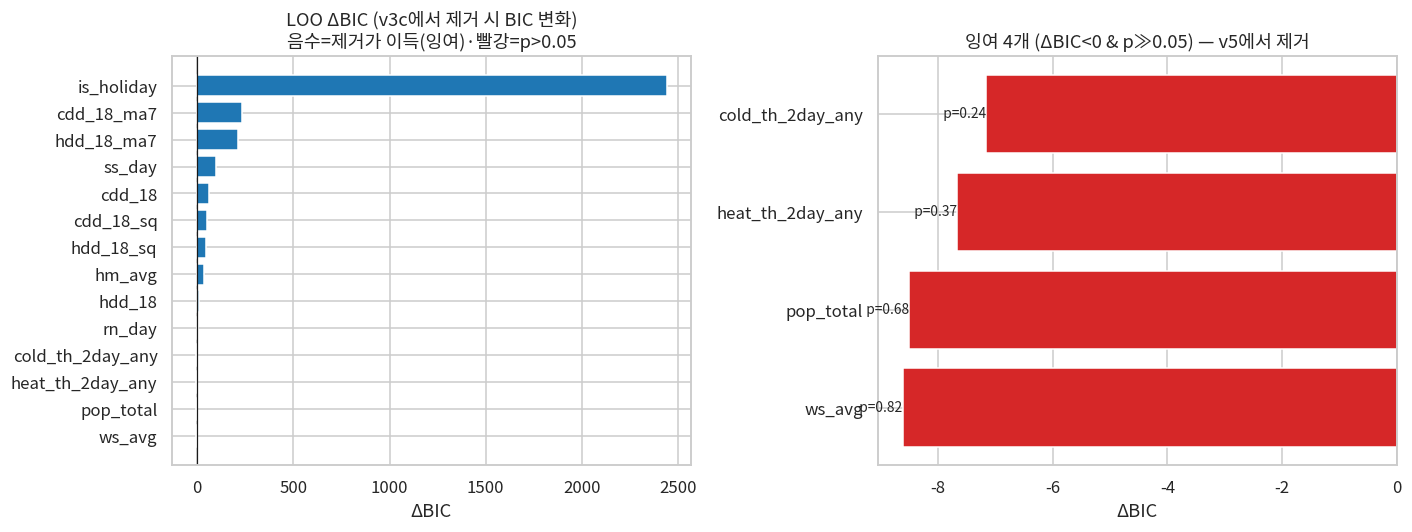

In [2]:
loo = abl[abl["phase"] == "LOO"].copy().sort_values("dBIC")
red = loo["p_in_full"] > 0.05
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].barh(loo["var"], loo["dBIC"], color=np.where(red, "tab:red", "tab:blue"))
ax[0].axvline(0, color="k", lw=.8)
ax[0].set_title("LOO ΔBIC (v3c에서 제거 시 BIC 변화)\n음수=제거가 이득(잉여)·빨강=p>0.05")
ax[0].set_xlabel("ΔBIC")
# 잉여 4개 확대
z = loo[loo["dBIC"] < 0]
ax[1].barh(z["var"], z["dBIC"], color="tab:red")
for y, (b, p) in enumerate(zip(z["dBIC"], z["p_in_full"])):
    ax[1].text(b, y, f"  p={p:.2f}", va="center", ha="right", fontsize=9)
ax[1].axvline(0, color="k", lw=.8)
ax[1].set_title("잉여 4개 (ΔBIC<0 & p≫0.05) — v5에서 제거")
ax[1].set_xlabel("ΔBIC")
plt.tight_layout(); plt.show()

## 2. BIC 후방제거 경로 — 14 → 10

매 라운드 BIC를 가장 낮추는 변수를 제거. 4번 제거 후엔 **어떤 제거도 BIC를 못 낮춰**
종료(=10개에서 수렴).

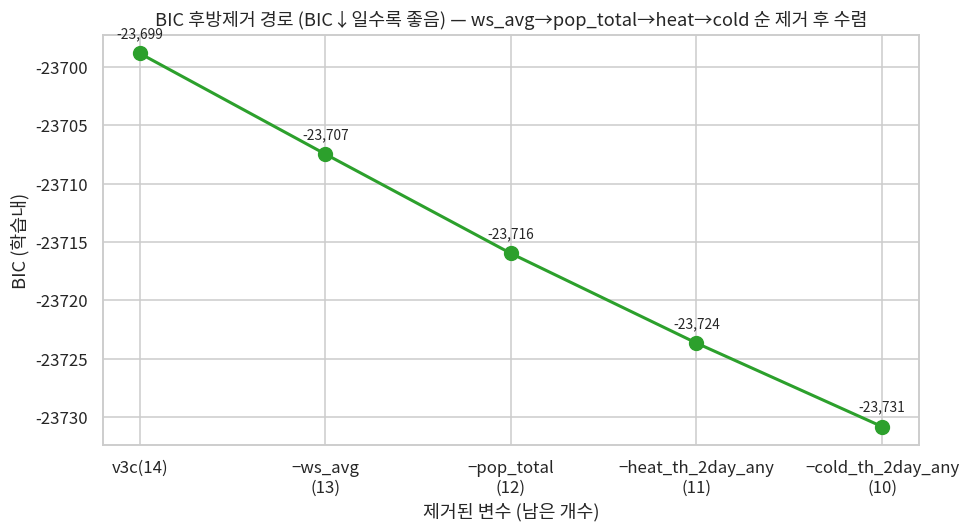

v5 = v3c − ['ws_avg', 'pop_total', 'heat_th_2day_any', 'cold_th_2day_any'] → 10 개


In [3]:
acc = abl["accepted"].map(lambda x: str(x).strip().lower() == "true")
path = abl[(abl["phase"] == "BIC_backward") & acc].sort_values("step")
steps = [14] + path["n_exog"].tolist()
bics  = [res.loc[res.model == "v3c", "BIC"].iloc[0]] + path["BIC"].tolist()
labels = ["v3c(14)"] + [f"−{v}\n({n})" for v, n in zip(path["var"], path["n_exog"])]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(len(bics)), bics, "o-", color="tab:green", lw=2, ms=9)
for i, b in enumerate(bics):
    ax.annotate(f"{b:,.0f}", (i, b), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set_title("BIC 후방제거 경로 (BIC↓일수록 좋음) — ws_avg→pop_total→heat→cold 순 제거 후 수렴")
ax.set_ylabel("BIC (학습내)"); ax.set_xlabel("제거된 변수 (남은 개수)")
plt.tight_layout(); plt.show()
print("v5 = v3c −", list(path["var"]), "→", int(path["n_exog"].iloc[-1]), "개")

## 3. v3c vs v5 — head-to-head

정보기준(AIC/BIC)은 v5가 더 낮고(좋고), rolling MAE도 v5가 미세 우위.
one-shot MAE·Winkler만 0.1~0.6% 비용 → **사실상 동등, 주모델은 v3c 유지**.

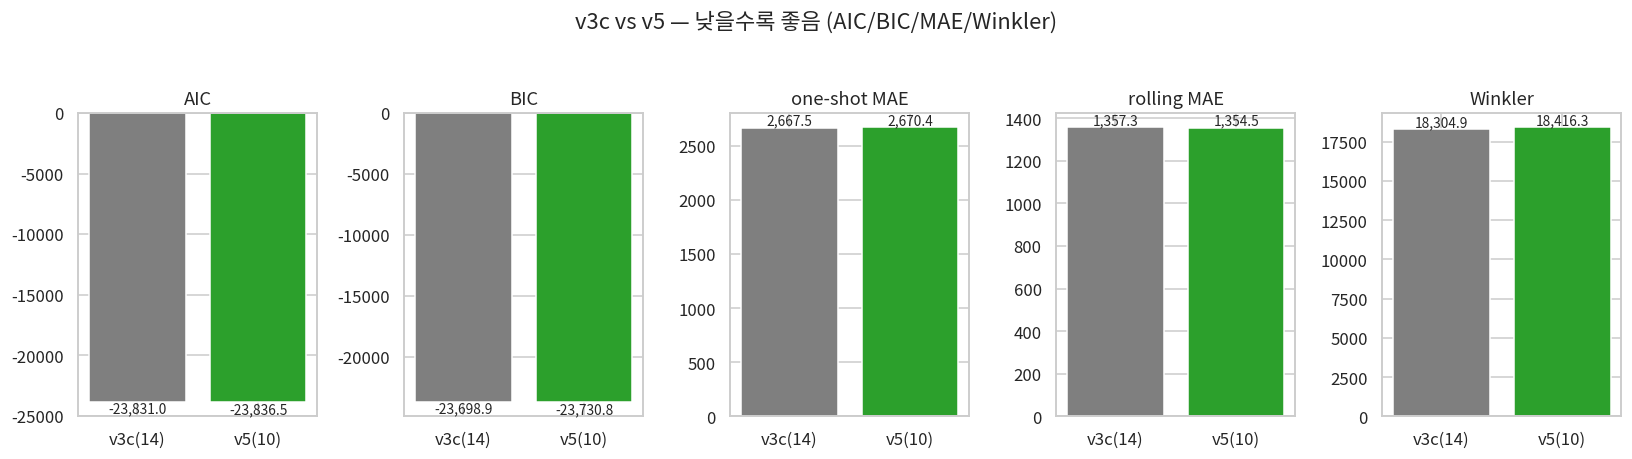

In [4]:
a = res.set_index("model")
pairs = [("AIC", "AIC"), ("BIC", "BIC"), ("MAE_2025", "one-shot MAE"),
         ("MAE_2025_rolling", "rolling MAE"), ("Winkler", "Winkler")]
fig, axes = plt.subplots(1, len(pairs), figsize=(15, 4))
for ax, (col, name) in zip(axes, pairs):
    vals = [a.loc["v3c", col], a.loc["v5_bic_backward", col]]
    bars = ax.bar(["v3c(14)", "v5(10)"], vals, color=["tab:gray", "tab:green"])
    ax.set_title(name)
    for r, v in zip(bars, vals):
        ax.text(r.get_x() + r.get_width()/2, v, f"{v:,.1f}", ha="center",
                va="bottom" if v >= 0 else "top", fontsize=9)
plt.suptitle("v3c vs v5 — 낮을수록 좋음 (AIC/BIC/MAE/Winkler)", y=1.04)
plt.tight_layout(); plt.show()

## 4. v5 예측 vs 실측 (2025 홀드아웃)

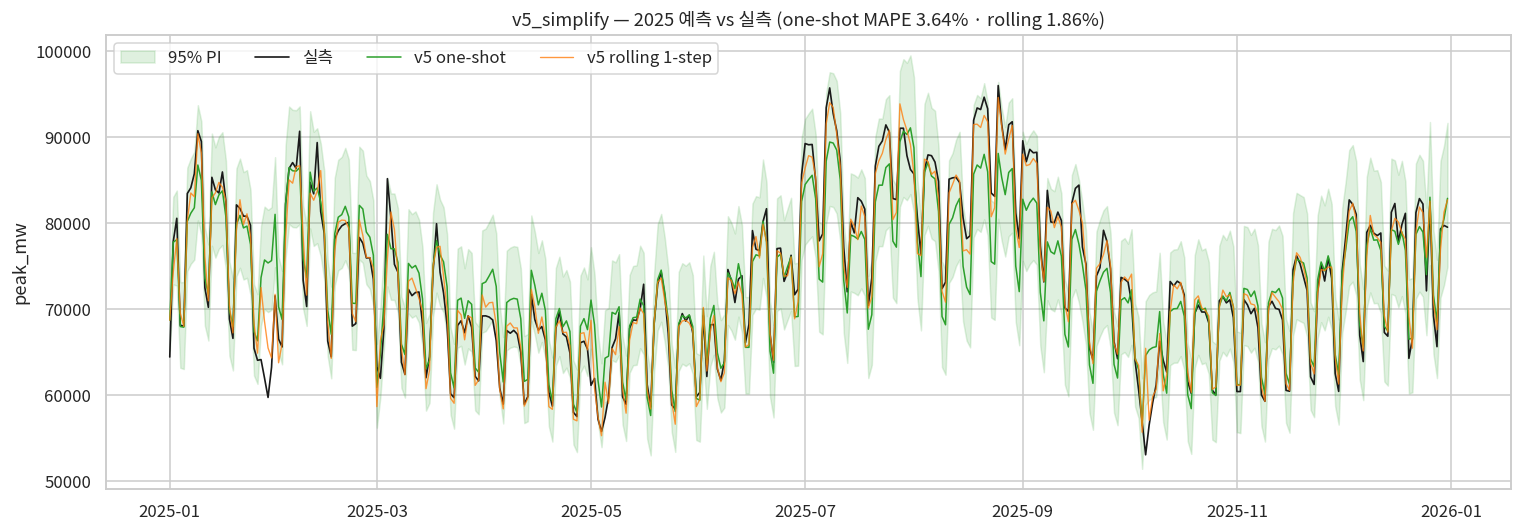

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(fc.index, fc["ci_low"], fc["ci_high"], color="tab:green", alpha=.15, label="95% PI")
ax.plot(fc.index, fc["actual"], color="k", lw=1.1, label="실측")
ax.plot(fc.index, fc["pred"], color="tab:green", lw=1.0, label="v5 one-shot")
ax.plot(fc.index, fc["rolling"], color="tab:orange", lw=.9, alpha=.8, label="v5 rolling 1-step")
ax.set_title("v5_simplify — 2025 예측 vs 실측 (one-shot MAPE 3.64% · rolling 1.86%)")
ax.set_ylabel("peak_mw"); ax.legend(ncol=4)
plt.tight_layout(); plt.show()

### 결론

- greedy·BIC·AIC **세 절차가 동일한 4개**를 잉여로 지목(삼중 수렴).
- v5(10개)는 v3c보다 AIC −5.5·BIC −32, rolling MAE −2.8 → **간결하면서 동등 이상**.
- 비용은 one-shot MAE +0.11%·Winkler +0.6%뿐 → **주모델 v3c 유지**, v5는 "14→10 동등"
  robustness 근거(`src/MODELS.md`).